# Experimento de regressão simbólica para OTFTs

Notebook para preparar os dados p-OTFT da Org1 e executar o pipeline original LLM-SR com parâmetros explícitos e resultados registrados na pasta da execução.

A curva selecionada é a transferência com |VDS| nominal de 50 V. O alvo é log10(|ID|/A); os 20% finais da varredura ordenada ficam reservados para extrapolação. O modelo é empírico e unidimensional. O modo smoke permite exercitar o pipeline sem servidor LLM.

## 1. Ambiente e caminhos

Execute com o ambiente Conda llmsr ativo. As dependências são as definidas pelo repositório LLM-SR. Este notebook localiza o workspace a partir do diretório corrente.

In [8]:
from pathlib import Path
import random
import socket
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_workspace(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "LLM-SR/main.py").is_file() and (candidate / "OTFT-SR/prepare_dataset.py").is_file():
            return candidate
    raise FileNotFoundError("Não encontrei o workspace contendo LLM-SR e OTFT-SR.")

WORKSPACE_ROOT = find_workspace(Path.cwd().resolve())
OTFT_SR_ROOT = WORKSPACE_ROOT / "OTFT-SR"
LLM_SR_ROOT = WORKSPACE_ROOT / "LLM-SR"
sys.path.insert(0, str(LLM_SR_ROOT))
sys.path.insert(0, str(OTFT_SR_ROOT))

from prepare_dataset import prepare_dataset
from llmsr import config as llmsr_config
from llmsr import evaluator as llmsr_evaluator
from llmsr import pipeline as llmsr_pipeline
from llmsr import sampler as llmsr_sampler

plt.style.use("seaborn-v0_8-whitegrid")
print("Workspace:", WORKSPACE_ROOT)
print("LLM-SR:", LLM_SR_ROOT)
print("OTFT-SR:", OTFT_SR_ROOT)

Workspace: /home/ymws/Documentos/llm-sr
LLM-SR: /home/ymws/Documentos/llm-sr/LLM-SR
OTFT-SR: /home/ymws/Documentos/llm-sr/OTFT-SR


## 2. Configuração reproduzível

Edite os parâmetros nesta célula antes da execução. RUN_PIPELINE inicia a busca e consulta o servidor local de completions. Deixe-o False para executar somente preparo, inspeção e gráficos.

In [9]:
SEED = 7
MAX_SAMPLE_NUMS = 100
SAMPLES_PER_PROMPT = 4
NUM_SAMPLERS = 1
NUM_EVALUATORS = 1
EVALUATE_TIMEOUT_SECONDS = 30
RUN_PIPELINE = True
SMOKE_MODE = False
LOCAL_LLM_HOST = "127.0.0.1"
LOCAL_LLM_PORT = 5000

if RUN_PIPELINE and not SMOKE_MODE:
    try:
        with socket.create_connection((LOCAL_LLM_HOST, LOCAL_LLM_PORT), timeout=2):
            print(f"Servidor LLM disponível em {LOCAL_LLM_HOST}:{LOCAL_LLM_PORT}.")
    except OSError as error:
        raise RuntimeError(
            "Servidor local LLM indisponível. Inicie o servidor em LLM-SR antes de habilitar RUN_PIPELINE."
        ) from error

random.seed(SEED)
np.random.seed(SEED)

Servidor LLM disponível em 127.0.0.1:5000.


## 3. Preparação e partição dos dados

O adaptador valida VDS, descarta a linha de unidades, aplica módulos à polarização e corrente do p-canal e gera o alvo logarítmico. A partição é contígua em |VGS| para que o teste represente extrapolação de alta tensão.

In [10]:
train_path, holdout_path = prepare_dataset()
train_df = pd.read_csv(train_path)
holdout_df = pd.read_csv(holdout_path)

assert list(train_df.columns) == ["VGS_abs_V", "log10_ID_abs_A"]
assert list(holdout_df.columns) == ["VGS_abs_V", "log10_ID_abs_A"]
assert train_df.notna().all().all() and holdout_df.notna().all().all()

partition_summary = pd.concat({
    "treino": train_df.describe().T[["count", "min", "max"]],
    "teste_extrapolacao": holdout_df.describe().T[["count", "min", "max"]],
}, axis=1)
display(partition_summary)
print(f"Treino: {len(train_df)} pontos | teste reservado: {len(holdout_df)} pontos")

treino                       teste_extrapolacao             \
                count        min        max              count        min   
VGS_abs_V        44.0   0.281955  39.849625               11.0  40.883457   
log10_ID_abs_A   44.0 -10.094204  -5.565431               11.0  -5.543634   

                           
                      max  
VGS_abs_V       49.906013  
log10_ID_abs_A  -5.136083

Treino: 44 pontos | teste reservado: 11 pontos


## 4. Inspeção da curva e da partição

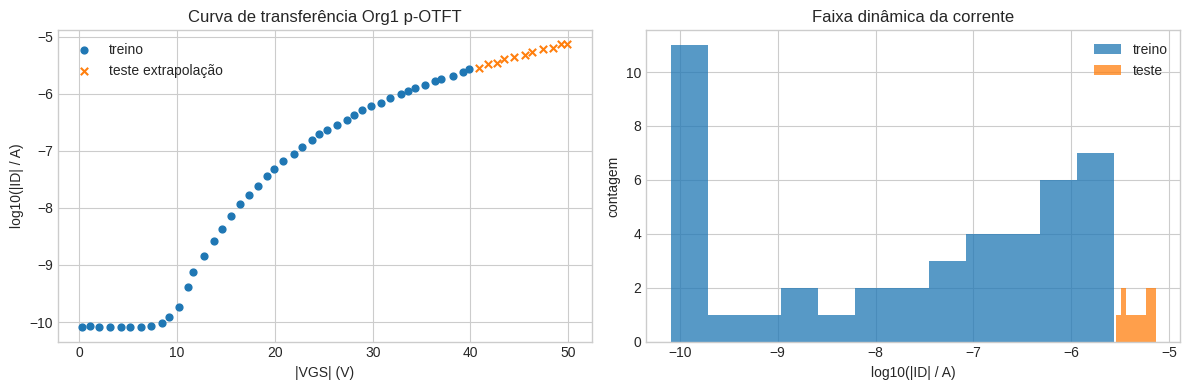

In [11]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(train_df.VGS_abs_V, train_df.log10_ID_abs_A, s=24, label="treino")
axes[0].scatter(holdout_df.VGS_abs_V, holdout_df.log10_ID_abs_A, s=28, marker="x", label="teste extrapolação")
axes[0].set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Curva de transferência Org1 p-OTFT")
axes[0].legend()
axes[1].hist(train_df.log10_ID_abs_A, bins=12, alpha=.75, label="treino")
axes[1].hist(holdout_df.log10_ID_abs_A, bins=8, alpha=.75, label="teste")
axes[1].set(xlabel="log10(|ID| / A)", ylabel="contagem", title="Faixa dinâmica da corrente")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Especificação científica e entrada do pipeline

A especificação limita a entrada a |VGS| e o alvo a log10(|ID|/A). A busca não recebe o holdout. O objeto dataset mantém o contrato usado pelo executor modular.

In [12]:
specification_path = OTFT_SR_ROOT / "specifications/otft_transfer_numpy.txt"
specification = specification_path.read_text(encoding="utf-8")
display(pd.DataFrame({"especificacao": [specification]}))

X_train = train_df[["VGS_abs_V"]].to_numpy(dtype=np.float64)
y_train = train_df["log10_ID_abs_A"].to_numpy(dtype=np.float64)
pipeline_dataset = {"data": {"inputs": X_train, "outputs": y_train}}
RUN_DIRECTORY = OTFT_SR_ROOT / "logs/notebook_org1_tipo_p"
print(f"Matriz de entrada: {X_train.shape}; vetor alvo: {y_train.shape}")
print("Diretório da rodada:", RUN_DIRECTORY)

,especificacao
0,"""""""\nDescubra uma expressão compacta para log1..."


Matriz de entrada: (44, 1); vetor alvo: (44,)
Diretório da rodada: /home/ymws/Documentos/llm-sr/OTFT-SR/logs/notebook_org1_tipo_p


## 6. Execução controlada do LLM-SR

O código abaixo chama diretamente llmsr.pipeline.main, igual ao executor modular. Para executar a busca real, confirme que o servidor local está ativo e altere RUN_PIPELINE para True na seção 2. Para validar somente a integração sem LLM, altere SMOKE_MODE para True e RUN_PIPELINE para True.

In [13]:
if RUN_PIPELINE:
    if SMOKE_MODE:
        class DeterministicSmokeLLM(llmsr_sampler.LLM):
            def draw_samples(self, prompt, config=None):
                del prompt, config
                return [
                    "    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * gate_voltage_abs**2"
                ]
        llm_class = DeterministicSmokeLLM
    else:
        llm_class = llmsr_sampler.LocalLLM

    class_config = llmsr_config.ClassConfig(
        llm_class=llm_class,
        sandbox_class=llmsr_evaluator.LocalSandbox,
    )
    experiment_config = llmsr_config.Config(
        samples_per_prompt=SAMPLES_PER_PROMPT,
        num_samplers=NUM_SAMPLERS,
        num_evaluators=NUM_EVALUATORS,
        evaluate_timeout_seconds=EVALUATE_TIMEOUT_SECONDS,
        use_api=False,
        problem_name="org1_otft_transfer",
    )
    RUN_DIRECTORY.mkdir(parents=True, exist_ok=True)
    llmsr_sampler.Sampler._global_samples_nums = 1

    llmsr_pipeline.main(
        specification=specification,
        inputs=pipeline_dataset,
        config=experiment_config,
        max_sample_nums=MAX_SAMPLE_NUMS,
        class_config=class_config,
        log_dir=str(RUN_DIRECTORY),
    )
else:
    print("Execução desabilitada. Ajuste RUN_PIPELINE na seção 2 para iniciar a busca.")

INFO:absl:Best score of island 0 increased to -0.1296525436015593
INFO:absl:Best score of island 1 increased to -0.1296525436015593
INFO:absl:Best score of island 2 increased to -0.1296525436015593
INFO:absl:Best score of island 3 increased to -0.1296525436015593
INFO:absl:Best score of island 4 increased to -0.1296525436015593
INFO:absl:Best score of island 5 increased to -0.1296525436015593
INFO:absl:Best score of island 6 increased to -0.1296525436015593
INFO:absl:Best score of island 7 increased to -0.1296525436015593
INFO:absl:Best score of island 8 increased to -0.1296525436015593
INFO:absl:Best score of island 9 increased to -0.1296525436015593


================= Evaluated Function =================
def equation(gate_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Equação empírica para log10(|ID|/A) ao longo da curva de transferência."""
    return parameters[0] + parameters[1] * gate_voltage_abs
------------------------------------------------------
Score        : -0.1296525436015593
Sample time  : None
Evaluate time: 0.05007219314575195
Sample orders: None




KeyboardInterrupt: 

## 7. Revisão dos artefatos da rodada

Os parâmetros ajustados durante a avaliação não são persistidos pelo pipeline original nos JSONs de amostras. Os scores representam -MSE no treino logarítmico. Consulte o notebook de análise de logs para sumarização e gráficos comparativos.

In [ ]:
if RUN_DIRECTORY.exists():
    sample_files = sorted((RUN_DIRECTORY / "samples").glob("samples_*.json"))
    print(f"Amostras registradas: {len(sample_files)}")
    for path in sample_files[-5:]:
        print(path.name)
else:
    print("Ainda não há diretório de logs para esta rodada.")

Amostras registradas: 101
samples_95.json
samples_96.json
samples_97.json
samples_98.json
samples_99.json
